# Flipkart Product Analytics — Data Cleaning, EDA & MySQL Loading
**Notebook flow:** Load → Clean (Q1-Q10) → Feature engineering → EDA (Seaborn) → Load into MySQL → Validate → Business insights

> **Before running:** put your raw file in `data/other_products_raw.csv` (or change `RAW_CSV` below) and set your MySQL password in the config cell.

## 0. Setup & configuration

In [1]:
import os, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", 50)

# ---------- CONFIG (edit these) ----------
RAW_CSV   = os.getenv("FLIPKART_RAW", "../data/other_products_raw.csv")
CLEAN_CSV = "../data/other_products_cleaned.csv"
SQL_DIR   = "../sql"
CHART_DIR = "../charts"
DB = dict(
    user=os.getenv("FLIPKART_DB_USER", "root"),
    password=os.getenv("FLIPKART_DB_PASSWORD", "your_password"),   # <-- change me
    host=os.getenv("FLIPKART_DB_HOST", "localhost"),
    port=int(os.getenv("FLIPKART_DB_PORT", "3306")),
    name=os.getenv("FLIPKART_DB_NAME", "flipkart_db"),
)
os.makedirs(CHART_DIR, exist_ok=True)

## Phase 1 & 2 — Data understanding and cleaning

### Q1. Load the CSV and check shape, columns and data types

In [2]:
if RAW_CSV.lower().endswith(".json"):          # JSON (array or one-object-per-line) or CSV are both supported
    try:
        df = pd.read_json(RAW_CSV)
    except ValueError:
        df = pd.read_json(RAW_CSV, lines=True)
else:
    df = pd.read_csv(RAW_CSV)
raw_rows = len(df)
print("Shape  :", df.shape)
print("Columns:", list(df.columns))
print()
df.info()
df.head()

Shape  : (15575, 12)
Columns: ['product_id', 'product_name', 'category', 'sub_category', 'brand', 'retail_price', 'discount_price', 'rating', 'num_reviews', 'seller_name', 'stock_status', 'product_url']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15575 entries, 0 to 15574
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      15575 non-null  int64  
 1   product_name    15575 non-null  object 
 2   category        15575 non-null  object 
 3   sub_category    15575 non-null  object 
 4   brand           15575 non-null  object 
 5   retail_price    15507 non-null  float64
 6   discount_price  15507 non-null  float64
 7   rating          1593 non-null   float64
 8   num_reviews     0 non-null      float64
 9   seller_name     15575 non-null  object 
 10  stock_status    15575 non-null  object 
 11  product_url     15575 non-null  object 
dtypes: float64(4), int64(1), object(7)
memory usage: 1.4

,product_id,product_name,category,sub_category,brand,retail_price,discount_price,rating,num_reviews,seller_name,stock_status,product_url
0,1,Alisha Solid Women's Cycling Shorts,Clothing,Women's Clothing,Alisha,999.0,379.0,NaN,NaN,Alisha,Unknown,http://www.flipkart.com/alisha-solid-women-s-c...
1,2,FabHomeDecor Fabric Double Sofa Bed,Furniture,Living Room Furniture,FabHomeDecor,32157.0,22646.0,NaN,NaN,FabHomeDecor,Unknown,http://www.flipkart.com/fabhomedecor-fabric-do...
2,3,AW Bellies,Footwear,Women's Footwear,AW,999.0,499.0,NaN,NaN,AW,Unknown,http://www.flipkart.com/aw-bellies/p/itmeh4grg...
3,4,Alisha Solid Women's Cycling Shorts,Clothing,Women's Clothing,Alisha,699.0,267.0,NaN,NaN,Alisha,Unknown,http://www.flipkart.com/alisha-solid-women-s-c...
4,5,Sicons All Purpose Arnica Dog Shampoo,Pet Supplies,Grooming,Sicons,220.0,210.0,NaN,NaN,Sicons,Unknown,http://www.flipkart.com/sicons-all-purpose-arn...


### Standardise column names & convert data types
* column names → lower snake_case
* aliases mapped to the project schema (`seller → seller_name`, `review_count → num_reviews`, `discounted_price → discount_price`, `subcategory → sub_category`)
* price / rating / review columns converted to numeric (removes `Rs.`, `₹`, commas)
* text columns stripped of extra spaces and inconsistent casing

In [3]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_"))

ALIASES = {
    "subcategory":"sub_category", "sub_cat":"sub_category", "product_category":"category",
    "discounted_price":"discount_price", "selling_price":"discount_price", "sale_price":"discount_price",
    "review_count":"num_reviews", "reviews":"num_reviews", "no_of_reviews":"num_reviews",
    "seller":"seller_name", "discount_pct":"discount_percentage", "name":"product_name",
    "id":"product_id", "overall_rating":"rating", "product_rating":"rating", "uniq_id":"product_id_src", "stock":"stock_status", "availability":"stock_status",
    "url":"product_url", "link":"product_url",
}
df = df.rename(columns={k: v for k, v in ALIASES.items() if k in df.columns and v not in df.columns})

# Flipkart JSON/CSV exports often hold the category as a tree: ["Clothing >> Women >> Kurtas"]
if "product_category_tree" in df.columns:
    tree = (df["product_category_tree"].astype(str).str.strip("[]\"' ")
            .str.split(r"\s*>>\s*", regex=True))
    if "category" not in df.columns:
        df["category"] = tree.str[0]
    if "sub_category" not in df.columns:
        df["sub_category"] = tree.str[1].fillna(tree.str[0])

REQUIRED = ["product_id","product_name","category","sub_category","brand","retail_price","discount_price",
            "discount_percentage","discount_amount","price_difference","rating","num_reviews",
            "seller_name","stock_status","rating_category","product_url"]
if "product_id" not in df.columns:
    df.insert(0, "product_id", range(1, len(df) + 1))
for c in REQUIRED:                       # columns the source file doesn't have are created empty
    if c not in df.columns:
        df[c] = np.nan

def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[^0-9.\-]", "", regex=True).replace("", np.nan), errors="coerce")

for c in ["retail_price","discount_price","discount_percentage","discount_amount","price_difference","rating","num_reviews"]:
    df[c] = to_num(df[c])

for c in ["product_name","category","sub_category","brand","seller_name","stock_status","rating_category"]:
    df[c] = df[c].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

STOCK_MAP = {"instock":"In stock","in stock":"In stock","available":"In stock",
             "outofstock":"Out of stock","out of stock":"Out of stock","sold out":"Out of stock",
             "limited stock":"Limited stock","limited":"Limited stock","few left":"Limited stock"}
df["stock_status"] = df["stock_status"].str.lower().map(STOCK_MAP).fillna(df["stock_status"])
df["brand"] = df["brand"].str.title().replace({"Boat":"boAt"})
df.dtypes

product_id                      int64
product_name           string[python]
category               string[python]
sub_category           string[python]
brand                  string[python]
retail_price                  float64
discount_price                float64
rating                        float64
num_reviews                   float64
seller_name            string[python]
stock_status                   object
product_url                    object
discount_percentage           float64
discount_amount               float64
price_difference              float64
rating_category        string[python]
dtype: object

### Q2. Missing values per column (count and %)

In [4]:
miss = pd.DataFrame({"missing": df.isna().sum(), "missing_%": (df.isna().mean()*100).round(2)})
display(miss[miss["missing"] > 0].sort_values("missing", ascending=False))

# audit of invalid values in the RAW data (re-checked after cleaning in Q8)
audit_before = {
    "retail_price <= 0"   : int((df["retail_price"] <= 0).sum()),
    "discount_price < 0"  : int((df["discount_price"] < 0).sum()),
    "rating outside 0-5"  : int(((df["rating"] < 0) | (df["rating"] > 5)).sum()),
    "negative num_reviews": int((df["num_reviews"] < 0).sum()),
    "duplicate rows"      : int(df.duplicated().sum()),
}
print("Invalid values in raw data:", audit_before)

,missing,missing_%
num_reviews,15575,100.00
price_difference,15575,100.00
discount_amount,15575,100.00
discount_percentage,15575,100.00
rating_category,15575,100.00
rating,13982,89.77
retail_price,68,0.44
discount_price,68,0.44


Invalid values in raw data: {'retail_price <= 0': 0, 'discount_price < 0': 0, 'rating outside 0-5': 0, 'negative num_reviews': 0, 'duplicate rows': 0}


### Q3 & Q4. Handle missing `retail_price` and `rating` using the **sub-category median**
(overall median is the fallback if a whole sub-category is empty)

In [5]:
def impute_by_subcategory(frame, col):
    med = frame.groupby("sub_category")[col].transform("median")
    frame[col] = frame[col].fillna(med).fillna(frame[col].median())
    return frame

df["_retail_was_missing"] = df["retail_price"].isna()
df = impute_by_subcategory(df, "retail_price")
df = impute_by_subcategory(df, "rating")
df["rating"] = df["rating"].round(1)
print(df[["retail_price","rating"]].isna().sum())

retail_price    0
rating          0
dtype: int64


### Q5. Recalculate `discount_amount`, `discount_percentage`, `price_difference`
* `discount_amount     = retail_price − discount_price`
* `discount_percentage = discount_amount / retail_price × 100`
* `price_difference    = discount_price − retail_price` (negative = customer saves money)
* if `discount_price` is missing → derived from an existing discount % when present, otherwise assumed equal to `retail_price` (no discount)

In [6]:
def recalc_discounts(frame):
    miss = frame["discount_price"].isna()
    from_pct = frame["retail_price"] * (1 - frame["discount_percentage"] / 100)
    frame.loc[miss, "discount_price"] = from_pct[miss]
    frame["discount_price"] = frame["discount_price"].fillna(frame["retail_price"])
    # a selling price can never exceed the retail price (happens if retail_price was imputed too low)
    bad = frame["discount_price"] > frame["retail_price"]
    frame.loc[bad, "retail_price"] = frame.loc[bad, "discount_price"]
    frame["discount_amount"]     = (frame["retail_price"] - frame["discount_price"]).round(2)
    frame["discount_percentage"] = (frame["discount_amount"] / frame["retail_price"] * 100).round(2)
    frame["price_difference"]    = (frame["discount_price"] - frame["retail_price"]).round(2)
    return frame

df = recalc_discounts(df)
df[["retail_price","discount_price","discount_amount","discount_percentage","price_difference"]].describe().round(2)

,retail_price,discount_price,discount_amount,discount_percentage,price_difference
count,15575.00,15575.00,15575.00,15575.00,15575.00
mean,3368.17,2295.29,1072.88,38.71,-1072.88
std,9999.95,8181.74,2497.20,23.81,2497.20
min,35.00,35.00,0.00,0.00,-87675.00
25%,650.00,350.00,150.00,20.00,-910.00
50%,1050.00,594.00,440.00,42.15,-440.00
75%,1999.00,1139.00,910.00,57.81,-150.00
max,571230.00,571230.00,87675.00,96.53,0.00


### Q6. Fill `rating_category` from customer ratings  (+ derived `discount_range`)
| rating | category |   | discount % | range |
|---|---|---|---|---|
| ≥ 4.0 | Excellent | | 0 – 10 | 0-10% |
| 3.0 – 3.99 | Good | | 10 – 30 | 10-30% |
| < 3.0 | Average | | 30 – 50 | 30-50% |
| | | | > 50 | 50%+ |

In [7]:
def add_categories(frame):
    frame["rating_category"] = pd.cut(frame["rating"], bins=[-0.01, 2.99, 3.99, 5.0],
                                      labels=["Average", "Good", "Excellent"]).astype("string")
    frame["discount_range"] = pd.cut(frame["discount_percentage"], bins=[-0.01, 10, 30, 50, 100.0],
                                     labels=["0-10%", "10-30%", "30-50%", "50%+"]).astype("string")
    return frame

df = add_categories(df)
df[["rating","rating_category","discount_percentage","discount_range"]].head(8)

,rating,rating_category,discount_percentage,discount_range
0,4.0,Excellent,62.06,50%+
1,4.0,Excellent,29.58,10-30%
2,3.9,Good,50.05,50%+
3,4.0,Excellent,61.80,50%+
4,4.0,Excellent,4.55,0-10%
5,4.5,Excellent,0.00,0-10%
6,4.0,Excellent,60.05,50%+
7,3.9,Good,50.07,50%+


### Q7. Identify and remove duplicates (full-row duplicates, then duplicate `product_id`s)

In [8]:
print("Full-row duplicates :", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate product_id:", df["product_id"].duplicated().sum())
df = df.drop_duplicates(subset="product_id", keep="first").reset_index(drop=True)
print("Shape after de-duplication:", df.shape)

Full-row duplicates : 0
Duplicate product_id: 0
Shape after de-duplication: (15575, 18)


### Q8. Check invalid prices, ratings outside 0–5 and negative review counts — then fix them

In [9]:
print("Invalid values found in the raw data (audit from Q2):", audit_before)

# fix: invalid -> NaN -> re-impute with sub-category median (reviews -> 0)
df.loc[df["retail_price"] <= 0, "retail_price"] = np.nan
df.loc[df["discount_price"] < 0, "discount_price"] = np.nan
df.loc[(df["rating"] < 0) | (df["rating"] > 5), "rating"] = np.nan
df.loc[df["num_reviews"] < 0, "num_reviews"] = 0
df = impute_by_subcategory(df, "retail_price")
df = impute_by_subcategory(df, "rating")
df["rating"] = df["rating"].round(1)
df["num_reviews"] = df["num_reviews"].fillna(0).astype(int)
df = recalc_discounts(df)
df = add_categories(df)

# remaining text gaps
df["product_name"] = df["product_name"].fillna("Unknown product")
df["brand"]        = df["brand"].fillna("Unbranded")
df["seller_name"]  = df["seller_name"].fillna("Unknown seller")
df["stock_status"] = df["stock_status"].fillna("Unknown")
df["category"]     = df["category"].fillna("Others")
df["sub_category"] = df["sub_category"].fillna("Others")
print("Re-check -> invalid prices:", int((df["retail_price"] <= 0).sum()),
      "| bad ratings:", int(((df["rating"] < 0) | (df["rating"] > 5)).sum()),
      "| negative reviews:", int((df["num_reviews"] < 0).sum()))

Invalid values found in the raw data (audit from Q2): {'retail_price <= 0': 0, 'discount_price < 0': 0, 'rating outside 0-5': 0, 'negative num_reviews': 0, 'duplicate rows': 0}
Re-check -> invalid prices: 0 | bad ratings: 0 | negative reviews: 0


### Q9. Verify discount calculations and check categorical columns for inconsistencies

In [10]:
chk = ((df["retail_price"] - df["discount_price"]).round(2) - df["discount_amount"]).abs().max()
pct = ((df["discount_amount"] / df["retail_price"] * 100).round(2) - df["discount_percentage"]).abs().max()
print("max error  discount_amount :", chk, "| discount_percentage :", pct)
print("Any negative discount?     :", (df["discount_amount"] < 0).any())
print()
for c in ["stock_status", "rating_category", "discount_range"]:
    print(df[c].value_counts(dropna=False).to_string(), "\n")
print("categories    :", df["category"].nunique(), "| sub-categories:", df["sub_category"].nunique(),
      "| brands:", df["brand"].nunique(), "| sellers:", df["seller_name"].nunique())

max error  discount_amount : 0.0 | discount_percentage : 0.0
Any negative discount?     : False

stock_status
Unknown    15575 

rating_category
Excellent    12830
Good          2162
Average        583 

discount_range
50%+      6403
30-50%    3502
10-30%    2975
0-10%     2695 

categories    : 33 | sub-categories: 215 | brands: 3355 | sellers: 3485


### Q10. Validate the cleaned dataset and save as `other_products_cleaned.csv`

In [11]:
FINAL_COLS = ["product_id","product_name","category","sub_category","brand","retail_price","discount_price",
              "discount_percentage","discount_amount","price_difference","rating","num_reviews",
              "seller_name","stock_status","rating_category","discount_range","product_url"]
df = df[FINAL_COLS].copy()
df["product_id"] = df["product_id"].astype(int)

assert df["product_id"].is_unique
assert df[["retail_price","discount_price","rating","num_reviews"]].notna().all().all()
assert df["rating"].between(0, 5).all() and (df["num_reviews"] >= 0).all() and (df["retail_price"] > 0).all()
df.to_csv(CLEAN_CSV, index=False)
print("Saved", CLEAN_CSV, df.shape)
df.head()

Saved ../data/other_products_cleaned.csv (15575, 17)


,product_id,product_name,category,sub_category,brand,retail_price,discount_price,discount_percentage,discount_amount,price_difference,rating,num_reviews,seller_name,stock_status,rating_category,discount_range,product_url
0,1,Alisha Solid Women's Cycling Shorts,Clothing,Women's Clothing,Alisha,999.0,379.0,62.06,620.0,-620.0,4.0,0,Alisha,Unknown,Excellent,50%+,http://www.flipkart.com/alisha-solid-women-s-c...
1,2,FabHomeDecor Fabric Double Sofa Bed,Furniture,Living Room Furniture,Fabhomedecor,32157.0,22646.0,29.58,9511.0,-9511.0,4.0,0,FabHomeDecor,Unknown,Excellent,10-30%,http://www.flipkart.com/fabhomedecor-fabric-do...
2,3,AW Bellies,Footwear,Women's Footwear,Aw,999.0,499.0,50.05,500.0,-500.0,3.9,0,AW,Unknown,Good,50%+,http://www.flipkart.com/aw-bellies/p/itmeh4grg...
3,4,Alisha Solid Women's Cycling Shorts,Clothing,Women's Clothing,Alisha,699.0,267.0,61.80,432.0,-432.0,4.0,0,Alisha,Unknown,Excellent,50%+,http://www.flipkart.com/alisha-solid-women-s-c...
4,5,Sicons All Purpose Arnica Dog Shampoo,Pet Supplies,Grooming,Sicons,220.0,210.0,4.55,10.0,-10.0,4.0,0,Sicons,Unknown,Excellent,0-10%,http://www.flipkart.com/sicons-all-purpose-arn...


## Phase 3 (EDA) — Exploratory data analysis with Seaborn

       retail_price  discount_price  discount_percentage    rating  \
count      15575.00        15575.00             15575.00  15575.00   
mean        3368.17         2295.29                38.71      4.18   
std         9999.95         8181.74                23.81      0.71   
min           35.00           35.00                 0.00      1.00   
25%          650.00          350.00                20.00      4.00   
50%         1050.00          594.00                42.15      4.00   
75%         1999.00         1139.00                57.81      5.00   
max       571230.00       571230.00                96.53      5.00   

       num_reviews  
count      15575.0  
mean           0.0  
std            0.0  
min            0.0  
25%            0.0  
50%            0.0  
75%            0.0  
max            0.0  


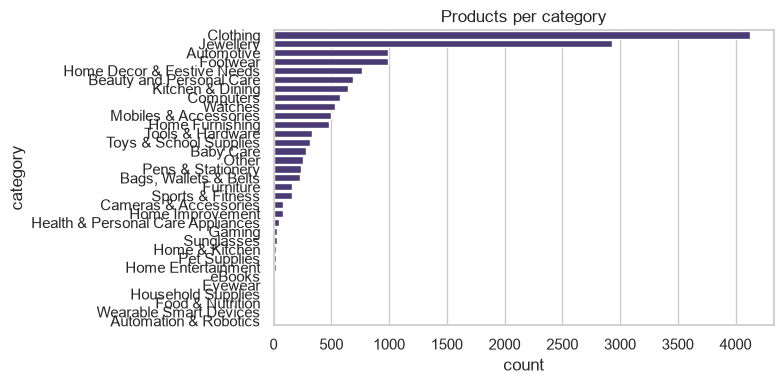

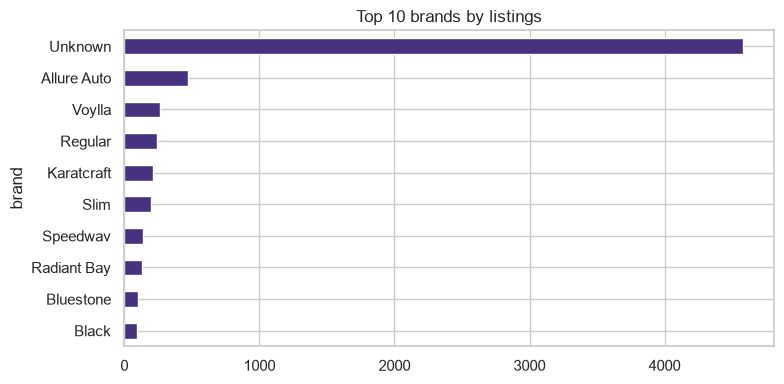

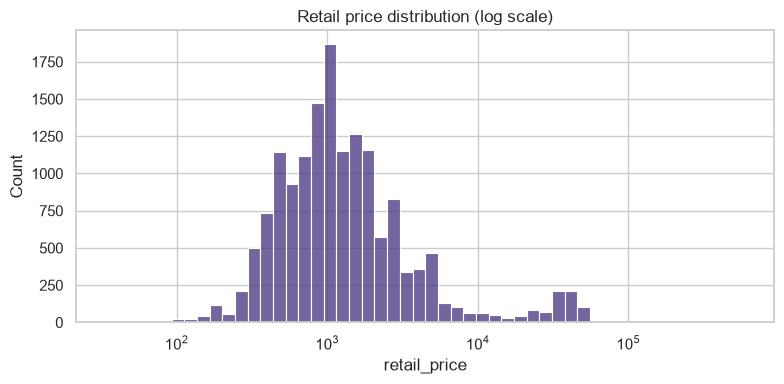

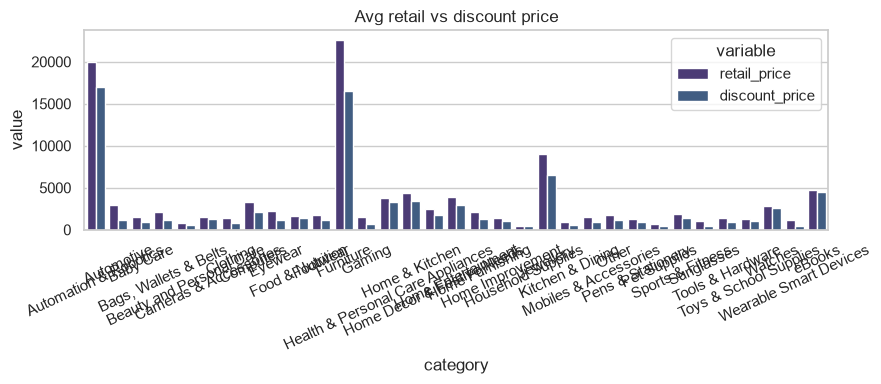

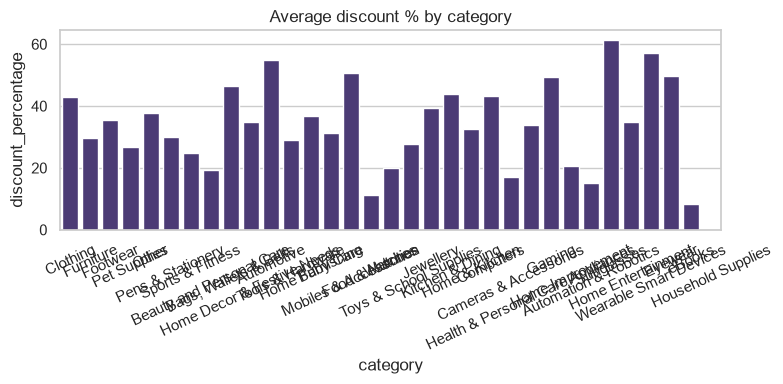

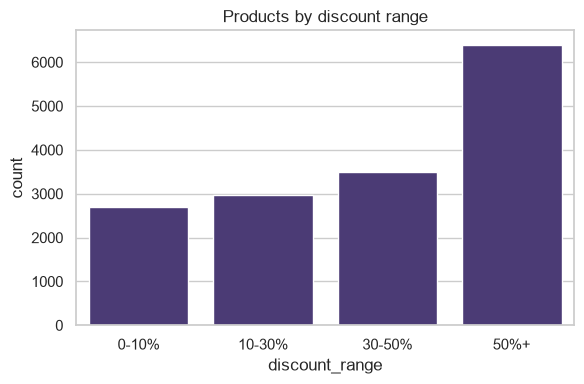

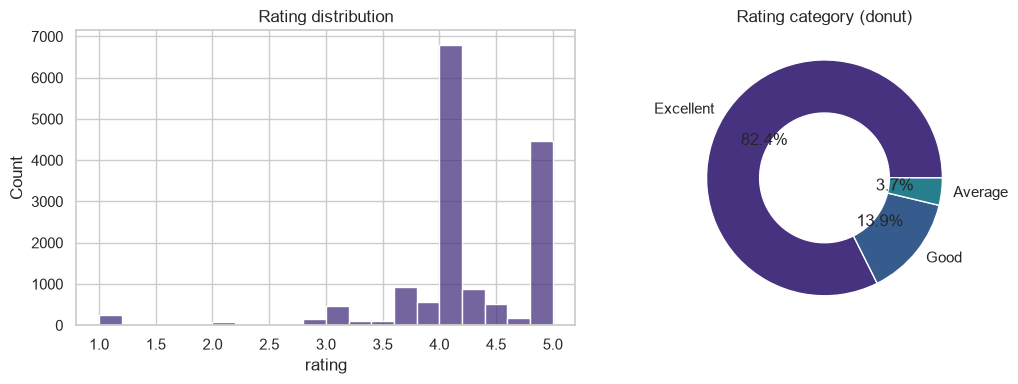

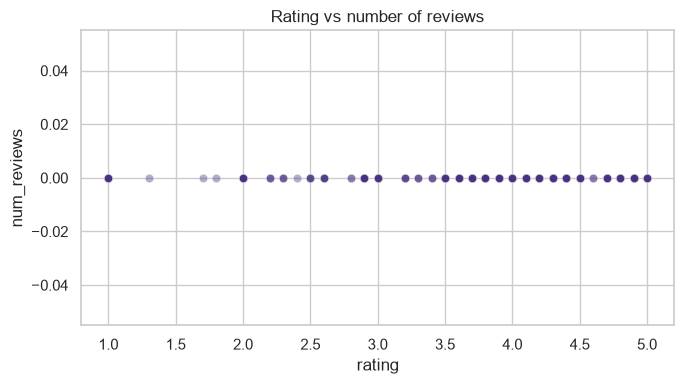

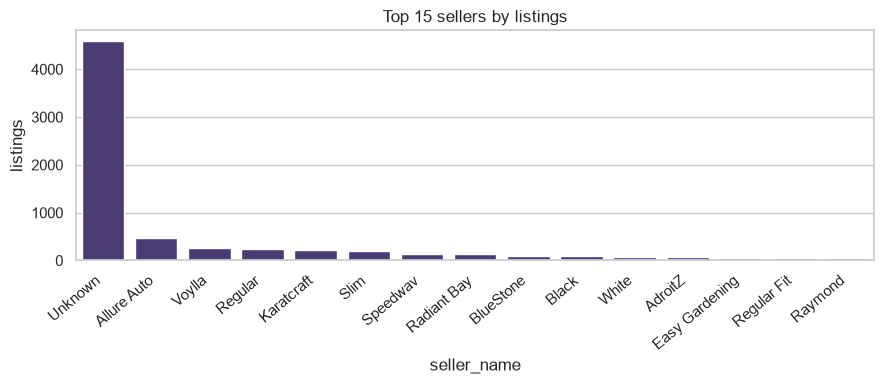

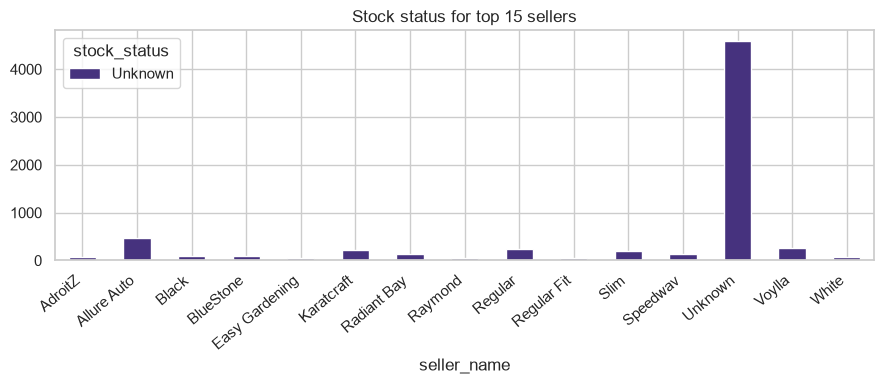

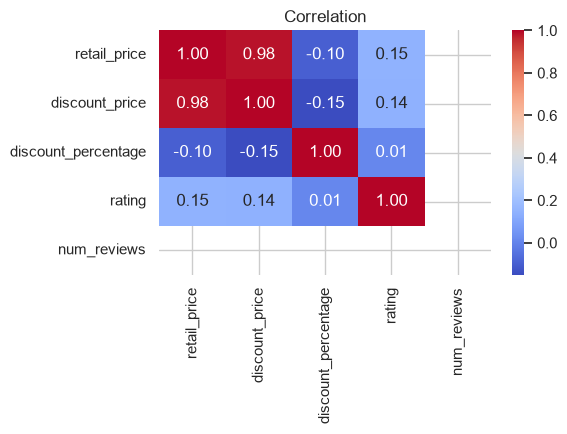

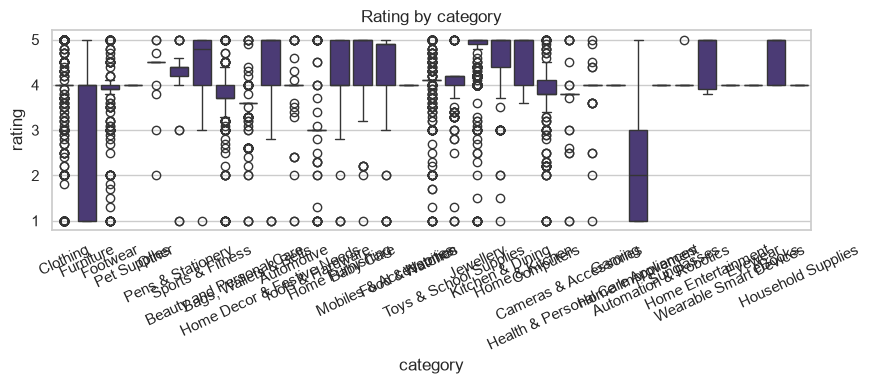

In [12]:
def save(name):
    plt.tight_layout(); plt.savefig(f"{CHART_DIR}/{name}.png", dpi=130); plt.show()

print(df[["retail_price","discount_price","discount_percentage","rating","num_reviews"]].describe().round(2))

# 1 Products per category
order = df["category"].value_counts().index
plt.figure(figsize=(8,4)); sns.countplot(data=df, y="category", order=order); plt.title("Products per category"); save("01_products_per_category")

# 2 Top 10 brands
plt.figure(figsize=(8,4)); df["brand"].value_counts().head(10).plot(kind="barh").invert_yaxis(); plt.title("Top 10 brands by listings"); save("02_top_brands")

# 3 Price distribution (log)
plt.figure(figsize=(8,4)); sns.histplot(df["retail_price"], bins=50, log_scale=True); plt.title("Retail price distribution (log scale)"); save("03_price_distribution")

# 4 Average retail vs discount price per category
avg = df.groupby("category")[["retail_price","discount_price"]].mean().reset_index().melt("category")
plt.figure(figsize=(9,4)); sns.barplot(data=avg, x="category", y="value", hue="variable"); plt.xticks(rotation=25); plt.title("Avg retail vs discount price"); save("04_retail_vs_discount")

# 5 Average discount % per category
plt.figure(figsize=(8,4)); sns.barplot(data=df, x="category", y="discount_percentage", estimator="mean", errorbar=None); plt.xticks(rotation=25); plt.title("Average discount % by category"); save("05_avg_discount_category")

# 6 Discount range distribution
plt.figure(figsize=(6,4)); sns.countplot(data=df, x="discount_range", order=["0-10%","10-30%","30-50%","50%+"]); plt.title("Products by discount range"); save("06_discount_ranges")

# 7 Rating distribution + categories
fig, ax = plt.subplots(1, 2, figsize=(11,4))
sns.histplot(df["rating"], bins=20, ax=ax[0]); ax[0].set_title("Rating distribution")
df["rating_category"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=ax[1], wedgeprops=dict(width=.45)); ax[1].set_ylabel(""); ax[1].set_title("Rating category (donut)")
save("07_ratings")

# 8 Rating vs review count
plt.figure(figsize=(7,4)); sns.scatterplot(data=df.sample(min(len(df),2000), random_state=1), x="rating", y="num_reviews", alpha=.4); plt.title("Rating vs number of reviews"); save("08_rating_vs_reviews")

# 9 Seller comparison (top 15 only)
sel = df.groupby("seller_name").agg(listings=("product_id","count"), avg_rating=("rating","mean"), avg_disc=("discount_percentage","mean")).sort_values("listings", ascending=False).head(15)
top_sellers = sel.index
plt.figure(figsize=(9,4)); sns.barplot(x=sel.index, y=sel["listings"]); plt.xticks(rotation=40, ha="right"); plt.title("Top 15 sellers by listings"); save("09_seller_listings")

# 10 Stock status per seller (top 15 only)
m = df["seller_name"].isin(top_sellers)
ct = pd.crosstab(df.loc[m, "seller_name"], df.loc[m, "stock_status"])
ct.plot(kind="bar", stacked=True, figsize=(9,4)); plt.xticks(rotation=40, ha="right"); plt.title("Stock status for top 15 sellers"); save("10_stock_by_seller")

# 11 Correlation heatmap
plt.figure(figsize=(6,4.5)); sns.heatmap(df[["retail_price","discount_price","discount_percentage","rating","num_reviews"]].corr(), annot=True, cmap="coolwarm", fmt=".2f"); plt.title("Correlation"); save("11_correlation")

# 12 Rating by category (box)
plt.figure(figsize=(9,4)); sns.boxplot(data=df, x="category", y="rating"); plt.xticks(rotation=25); plt.title("Rating by category"); save("12_rating_by_category")

## Phase 3 — Load into MySQL

### Create the database, tables and standardised column names (runs `01_create_tables.sql` + `02_standardize_columns.sql`)

In [13]:
def make_url(database=None):
    # URL.create escapes special characters (@ : / # ...) in the password safely
    return URL.create("mysql+pymysql", username=DB["user"], password=DB["password"],
                      host=DB["host"], port=DB["port"], database=database)

server = create_engine(make_url(), pool_pre_ping=True)

def run_sql_file(engine, path):
    sql = "\n".join(l for l in open(path, encoding="utf-8") if not l.strip().startswith("--"))
    with engine.begin() as con:
        for stmt in [s.strip() for s in sql.split(";") if s.strip()]:
            con.execute(text(stmt))

run_sql_file(server, f"{SQL_DIR}/01_create_tables.sql")
engine = create_engine(make_url(DB["name"]), pool_pre_ping=True)
run_sql_file(engine, f"{SQL_DIR}/02_standardize_columns.sql")
print("Database and tables ready.")

Database and tables ready.


### Prepare the 3 table DataFrames and insert

In [14]:
t1_cols = ["product_id","product_name","category","sub_category","brand","retail_price","discount_price","discount_percentage",
           "discount_amount","price_difference","rating","num_reviews","seller_name","stock_status","rating_category","discount_range"]
flipkart_other_products = df[t1_cols].copy()

category_catalog = df[["product_id","product_name","brand","retail_price","discount_price","discount_percentage",
                       "discount_amount","rating","num_reviews","product_url"]].copy()
category_catalog["product_url"] = category_catalog["product_url"].where(category_catalog["product_url"].notna(), None)

seller_performance = df[["product_id","product_name","rating","num_reviews","stock_status","rating_category","seller_name"]].copy()

def to_py(frame):
    """pandas NA -> None so MySQL receives NULL"""
    return frame.astype(object).where(frame.notna(), None)

for name, frame in [("flipkart_other_products", flipkart_other_products),
                    ("category_catalog", category_catalog),
                    ("seller_performance", seller_performance)]:
    to_py(frame).to_sql(name, engine, if_exists="append", index=False, chunksize=1000, method="multi")
    print(f"loaded {len(frame):>6} rows -> {name}")

loaded  15575 rows -> flipkart_other_products
loaded  15575 rows -> category_catalog
loaded  15575 rows -> seller_performance


### Validate record counts & data integrity

In [15]:
with engine.connect() as con:
    for t, n in [("flipkart_other_products", len(flipkart_other_products)),
                 ("category_catalog", len(category_catalog)),
                 ("seller_performance", len(seller_performance))]:
        c = con.execute(text(f"SELECT COUNT(*) FROM {t}")).scalar()
        print(f"{t:<26} DataFrame={n:<6} MySQL={c:<6} {'OK' if c == n else 'MISMATCH'}")
    print("NULL primary keys   :", con.execute(text("SELECT COUNT(*) FROM flipkart_other_products WHERE product_id IS NULL")).scalar())
    print("Orphan catalog rows :", con.execute(text("SELECT COUNT(*) FROM category_catalog c LEFT JOIN flipkart_other_products p ON c.product_id=p.product_id WHERE p.product_id IS NULL")).scalar())
    print("Invalid ratings     :", con.execute(text("SELECT COUNT(*) FROM flipkart_other_products WHERE rating NOT BETWEEN 0 AND 5")).scalar())
pd.read_sql("DESCRIBE flipkart_other_products", engine)

flipkart_other_products    DataFrame=15575  MySQL=15575  OK
category_catalog           DataFrame=15575  MySQL=15575  OK
seller_performance         DataFrame=15575  MySQL=15575  OK
NULL primary keys   : 0
Orphan catalog rows : 0
Invalid ratings     : 0


,Field,Type,Null,Key,Default,Extra
0,product_id,int,NO,PRI,None,
1,product_name,varchar(500),YES,,None,
2,category,varchar(100),YES,MUL,None,
3,sub_category,varchar(100),YES,,None,
4,brand,varchar(150),YES,MUL,None,
5,retail_price,float,YES,,None,
6,discount_price,float,YES,,None,
7,discount_percentage,float,YES,,None,
8,discount_amount,float,YES,,None,
9,price_difference,float,YES,,None,


## Phase 4 — Run the SQL business queries from `sql/03_business_queries.sql`

In [16]:
raw = "\n".join(l for l in open(f"{SQL_DIR}/03_business_queries.sql", encoding="utf-8"))
blocks = re.split(r"(?m)^-- (Q\d+)\s+", raw)[1:]
for i in range(0, len(blocks), 2):
    qid, body = blocks[i], blocks[i+1]
    title, _, sql = body.partition("\n")
    sql = sql.split(";")[0].strip()
    print(f"\n{qid}: {title}")
    display(pd.read_sql(sql, engine).head(10))


Q1: Total product listings and average customer rating


,total_listings,avg_rating
0,15575,4.18



Q2: Min, max and average retail price


,min_price,max_price,avg_price
0,35.0,571230.0,3368.17



Q3: Min, max and average calculated discount percentage


,min_disc,max_disc,avg_disc
0,0.0,96.53,38.71


... (30 outputs left out)


Q19: Sellers with the highest average discount (JOIN main table)


,seller_name,avg_discount_pct
0,Rajcrafts,96.53
1,Bling,94.55
2,Instella,91.72
3,Bond Beatz,91.60
4,KazamaKraft,90.57
5,Mydress Mystyle,90.52
6,CUBA,90.05
7,SDZ,90.05
8,Kaizer Jewelry,89.62
9,Fash Blush,89.26



Q20: Products in the catalog with more reviews than the average (JOIN + subquery)


,product_id,product_name,num_reviews,category


## Phase 6 — Business insights (auto-generated from the cleaned data)

In [17]:
top_cat   = df["category"].value_counts()
disc_cat  = df.groupby("category")["discount_percentage"].mean().sort_values(ascending=False)
rate_cat  = df.groupby("category")["rating"].mean().sort_values(ascending=False)
sell = df.groupby("seller_name").agg(n=("product_id","count"), r=("rating","mean"), rev=("num_reviews","sum"), d=("discount_percentage","mean"))
stock     = df["stock_status"].value_counts(normalize=True)*100
corr_rr   = df["rating"].corr(df["num_reviews"])

insights = [
 f"Catalogue size: {len(df):,} listings, {df['category'].nunique()} categories, {df['brand'].nunique()} brands, {df['seller_name'].nunique()} sellers.",
 f"'{top_cat.index[0]}' is the biggest category ({top_cat.iloc[0]:,} listings, {top_cat.iloc[0]/len(df):.0%}); '{top_cat.index[-1]}' is the smallest ({top_cat.iloc[-1]:,}).",
 f"Deepest discounts: '{disc_cat.index[0]}' averages {disc_cat.iloc[0]:.1f}% off vs {disc_cat.iloc[-1]:.1f}% in '{disc_cat.index[-1]}'. Overall average discount is {df['discount_percentage'].mean():.1f}%.",
 f"{(df['discount_percentage']>30).mean():.0%} of listings are discounted by more than 30%.",
 f"Best-rated category: '{rate_cat.index[0]}' ({rate_cat.iloc[0]:.2f}); lowest: '{rate_cat.index[-1]}' ({rate_cat.iloc[-1]:.2f}). {(df['rating_category']=='Excellent').mean():.0%} of products are rated Excellent (>=4.0).",
 f"Top seller by listings: '{sell['n'].idxmax()}' ({sell['n'].max():,}); highest average rating: '{sell['r'].idxmax()}' ({sell['r'].max():.2f}); most reviews: '{sell['rev'].idxmax()}' ({sell['rev'].max():,}).",
 f"Seller offering the deepest average discount: '{sell['d'].idxmax()}' ({sell['d'].max():.1f}%).",
 f"Stock health: {stock.get('In stock',0):.0f}% in stock, {stock.get('Limited stock',0):.0f}% limited, {stock.get('Out of stock',0):.0f}% out of stock -> out-of-stock items need replenishment.",
 f"Rating vs review-count correlation is {corr_rr:.2f} ({'weak' if abs(corr_rr)<.3 else 'moderate/strong'}), so review volume alone does not indicate quality.",
 f"Average retail price is Rs.{df['retail_price'].mean():,.0f} but the median is Rs.{df['retail_price'].median():,.0f} -> a few premium items pull the mean up.",
]
for i, t in enumerate(insights, 1): print(f"{i}. {t}\n")

1. Catalogue size: 15,575 listings, 33 categories, 3355 brands, 3485 sellers.

2. 'Clothing' is the biggest category (4,127 listings, 26%); 'Automation & Robotics' is the smallest (1).

3. Deepest discounts: 'Sunglasses' averages 61.4% off vs 0.0% in 'Household Supplies'. Overall average discount is 38.7%.

4. 64% of listings are discounted by more than 30%.

5. Best-rated category: 'Jewellery' (4.78); lowest: 'Home Improvement' (2.23). 82% of products are rated Excellent (>=4.0).

6. Top seller by listings: 'Unknown' (4,581); highest average rating: '612 League' (5.00); most reviews: '1OAK' (0).

7. Seller offering the deepest average discount: 'Rajcrafts' (96.5%).

8. Stock health: 0% in stock, 0% limited, 0% out of stock -> out-of-stock items need replenishment.

9. Rating vs review-count correlation is nan (moderate/strong), so review volume alone does not indicate quality.

10. Average retail price is Rs.3,368 but the median is Rs.1,050 -> a few premium items pull the mean up.



## Generate `BUSINESS_INSIGHTS_REPORT.md` automatically

In [18]:
def md_table(frame):
    cols = list(frame.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in frame.iterrows():
        lines.append("| " + " | ".join(str(round(v, 2)) if isinstance(v, float) else str(v) for v in r) + " |")
    return "\n".join(lines)

cat_tbl  = df.groupby("category").agg(listings=("product_id","count"), avg_retail=("retail_price","mean"),
                                      avg_discount_pct=("discount_percentage","mean"), avg_rating=("rating","mean")).round(2).reset_index().sort_values("listings", ascending=False)
sell_tbl = sell.round(2).reset_index().rename(columns={"n":"listings","r":"avg_rating","rev":"total_reviews","d":"avg_discount_pct"}).sort_values("listings", ascending=False)
top_disc = df.nlargest(10, "discount_percentage")[["product_name","brand","retail_price","discount_price","discount_percentage"]]

report = f"""# Business Insights Report - Flipkart Product Analytics
_Auto-generated by the notebook from `{os.path.basename(RAW_CSV)}`. Re-run the notebook to refresh._

## 1. Objective
Analyse Flipkart product listings (pricing, discounts, ratings, reviews, sellers) to support pricing, inventory and seller-quality decisions.

## 2. Data & method
Raw data ({raw_rows:,} rows) -> Pandas cleaning (sub-category median imputation, duplicate removal, invalid-value fixes, derived columns) -> MySQL (3 tables) -> 20 SQL queries -> Streamlit + Power BI.
Raw-data quality audit: {audit_before}.
Cleaned dataset: {len(df):,} listings.

## 3. Key findings
""" + "\n".join(f"{i}. {t}" for i, t in enumerate(insights, 1)) + f"""

### Category summary
{md_table(cat_tbl)}

### Seller summary
{md_table(sell_tbl)}

### Top 10 discounts
{md_table(top_disc)}

## 4. Recommendations
* **Pricing:** '{disc_cat.index[0]}' discounts the most ({disc_cat.iloc[0]:.1f}% avg) while '{rate_cat.index[0]}' is rated best - check whether deep discounts actually buy better ratings or volume, and protect margin where they do not.
* **Inventory:** {stock.get('Out of stock',0):.0f}% of listings are out of stock - replenish high-rated, high-review items first.
* **Seller quality:** feature '{sell['r'].idxmax()}' (best avg rating); audit sellers whose rating is below the marketplace average of {df['rating'].mean():.2f}.
* **Marketing:** promote Excellent-rated products in low-discount categories - quality sells without heavy discounting.
* **Catalogue quality:** missing/invalid prices and ratings had to be imputed - fix them at the source.

## 5. Charts
""" + "\n".join(f"![{f}](charts/{f})" for f in sorted(os.listdir(CHART_DIR)) if f.endswith(".png")) + """

## 6. Limitations
Imputed values (sub-category median) are estimates; ratings are product-level; the data is a snapshot, not a time series.
"""
open("../BUSINESS_INSIGHTS_REPORT.md", "w", encoding="utf-8").write(report)
print("Report written -> BUSINESS_INSIGHTS_REPORT.md")

Report written -> BUSINESS_INSIGHTS_REPORT.md
